# Example of the aitlas toolbox in the context of object detection 

This notebook shows a sample implementation of object detection using the aitlas toolbox. The SWIM dataset contains ship wakes annotated with oriented bounding boxes. For ease of use, this notebook considers the bounding boxes translated into axis-aligned.

## Import the required packages

In [ ]:
from aitlas.datasets import SWIMDataset
from aitlas.transforms import Resize
from aitlas.utils import image_loader
from aitlas.models import FasterRCNN

## Visualize images and objects with bounding boxes

In [42]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/SWIM_ship/SWIM_Dataset_1.0.0/JPEGImages",
    "annotation_dir": "/home/dragik/data/FAIR_EO/SWIM_ship/SWIM_Dataset_1.0.0/Annotations",
}
dataset = SWIMDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 11600


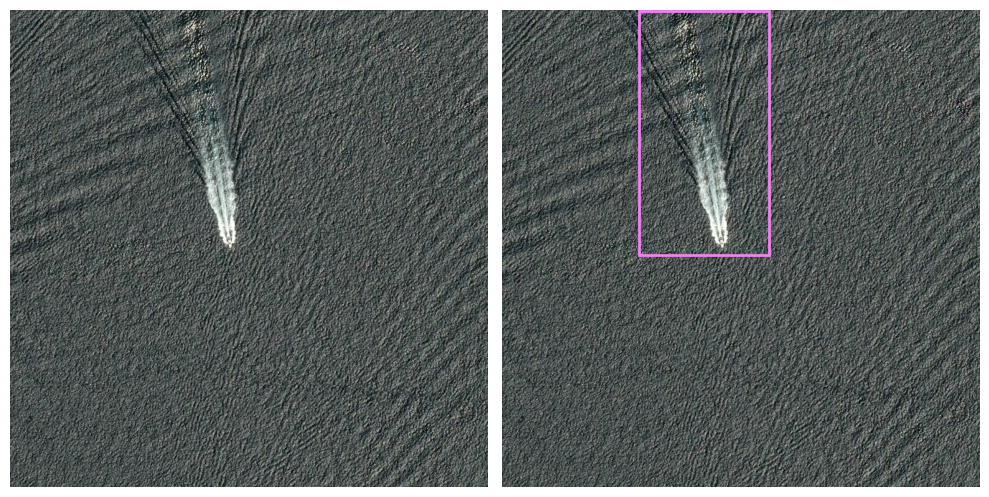

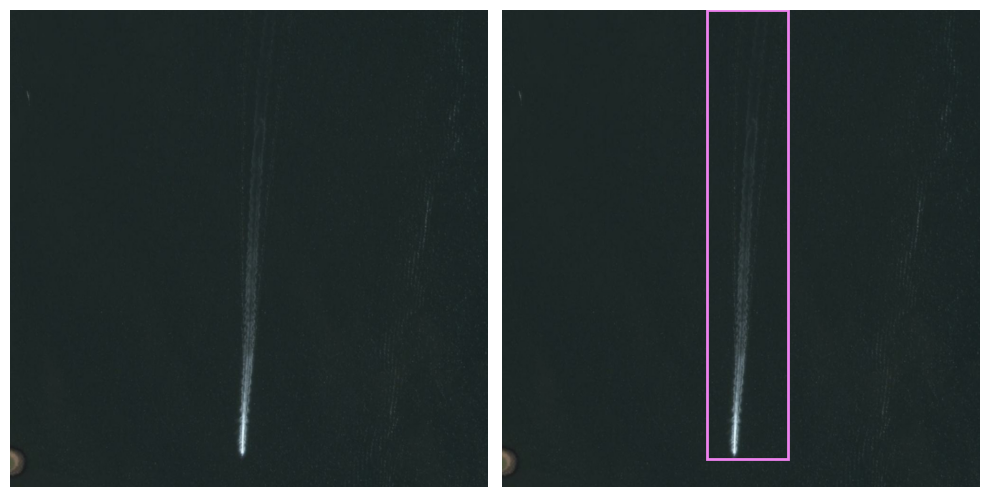

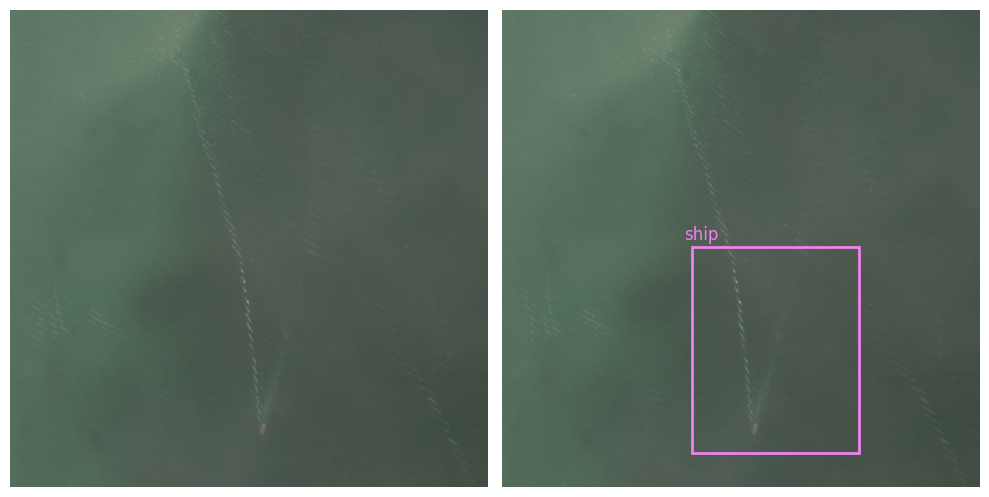

In [15]:
dataset.show_image(65);
dataset.show_image(100);
dataset.show_image(200);

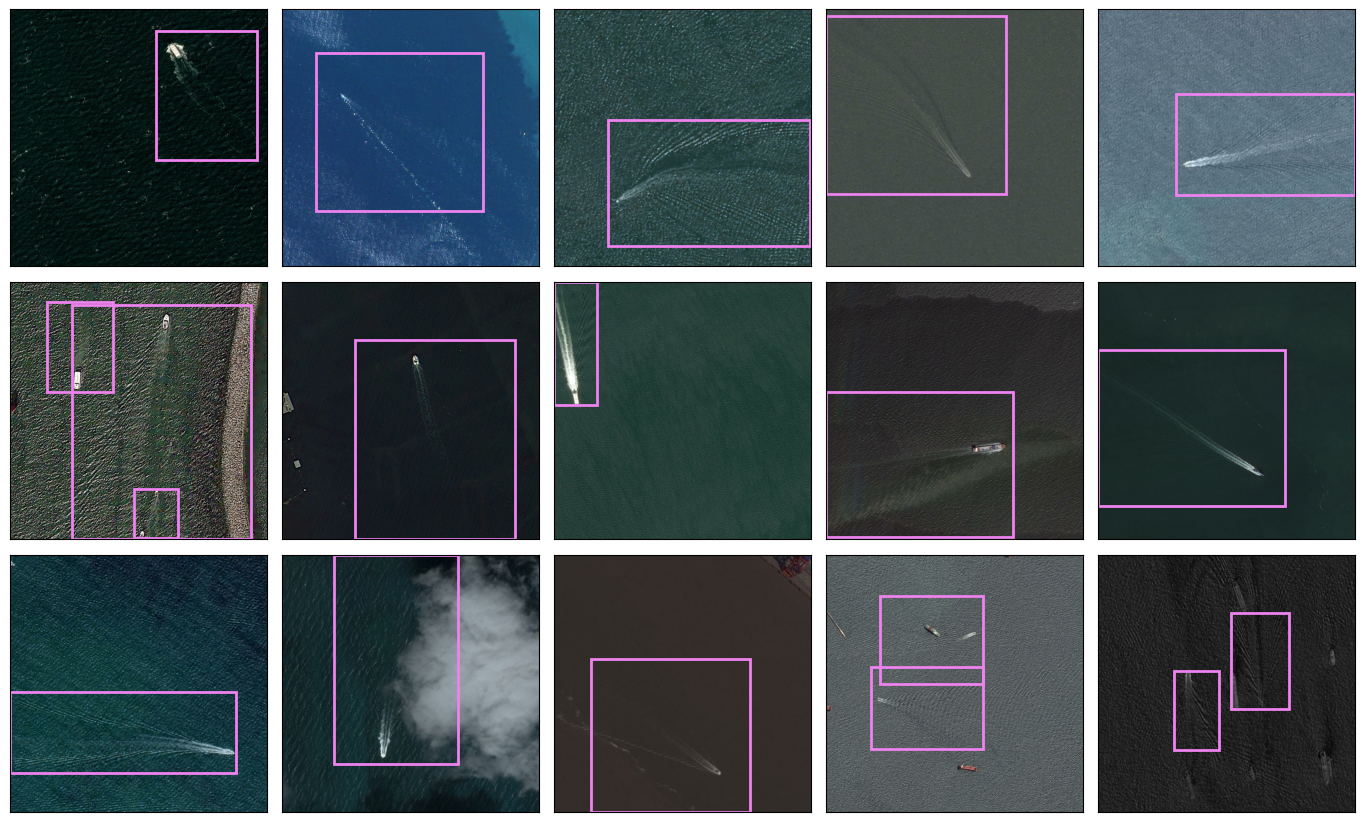

In [18]:
dataset.show_batch(15);

In [43]:
dataset.data_distribution_table()

,Label,Count
0,ship wake,15356


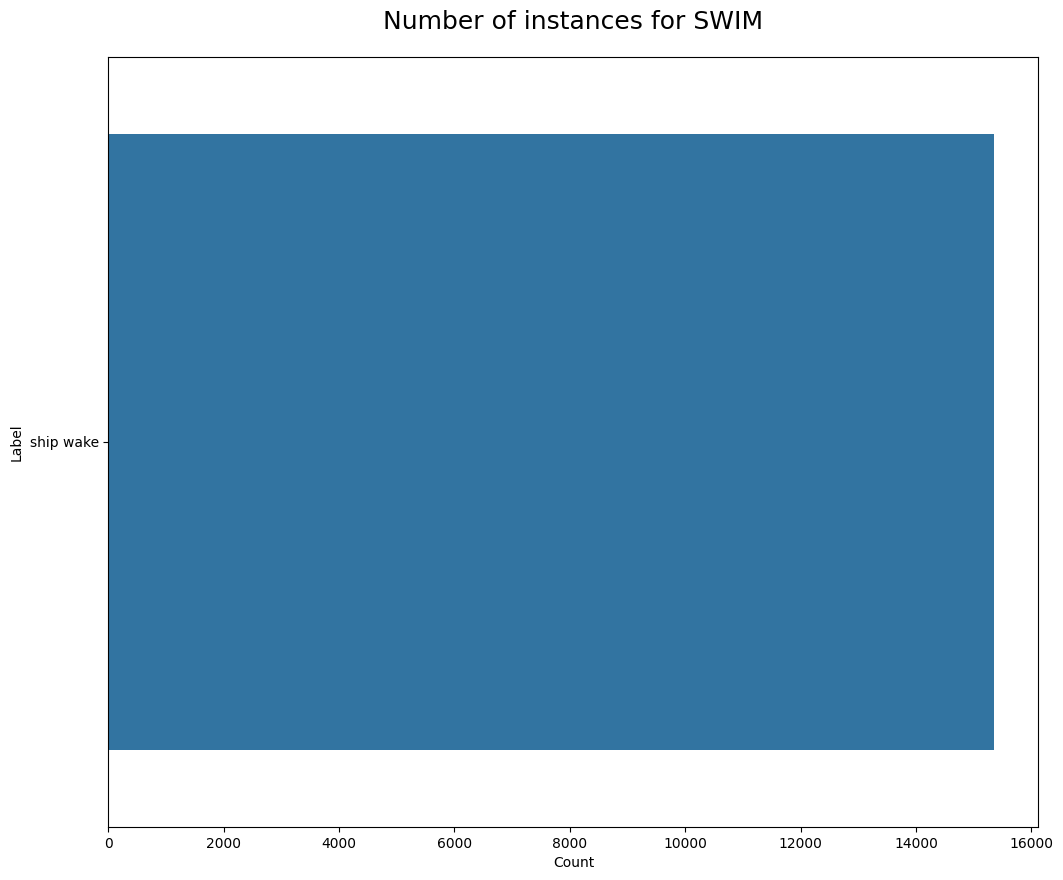

In [44]:
dataset.data_distribution_barchart();

## Load train data

In [5]:
train_dataset_config = {
    "batch_size": 16,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/SWIM_ship/SWIM_Dataset_1.0.0/JPEGImages",
    "annotation_dir": "/home/dragik/data/FAIR_EO/SWIM_ship/SWIM_Dataset_1.0.0/Annotations",
    "csv_file": "/home/dragik/data/FAIR_EO/SWIM_ship/SWIM_Dataset_1.0.0/ImageSets/Main/train.txt",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}
train_dataset = SWIMDataset(train_dataset_config)

print(f"Total number of train images: {len(train_dataset)}")

Total number of train images: 6960


## Create the model

In [6]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/experiments/SWIM_ship/"
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}

model = FasterRCNN(model_config)
model.prepare()

## Start the training

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-09-26 07:40:29,662 INFO Starting training.
training: 100%|██████████| 435/435 [05:10<00:00,  1.40it/s]
2025-09-26 07:45:40,896 INFO epoch: 1, time: 311, loss:  0.17854
testing on train set: 100%|██████████| 435/435 [03:53<00:00,  1.86it/s]
2025-09-26 07:49:42,191 INFO map:0.42610540986061096, map_50:0.7866010069847107, map_75:0.4228116273880005, map_small:0.16701437532901764, map_medium:0.2723575234413147, map_large:0.44224148988723755, mar_1:0.41805586218833923, mar_10:0.5342931151390076, mar_100:0.5355704426765442, mar_small:0.3132352828979492, mar_medium:0.4138568043708801, mar_large:0.5501324534416199, map_per_class:0.42610540986061096, mar_100_per_class:0.5355704426765442, classes:1.0
training: 100%|██████████| 435/435 [05:22<00:00,  1.35it/s]
2025-09-26 07:55:04,785 INFO epoch: 2, time: 322, loss:  0.13878
testing on train set: 100%|██████████| 435/435 [03:46<00:00,  1.92it/s]
2025-09-26 07:58:57,206 INFO map:0.5170063376426697, map_50:0.8536269068717957, map_75:0.5656024813

0.05618165557154979

## Evaluate the model

In [8]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "data_dir": "/home/dragik/data/FAIR_EO/SWIM_ship/SWIM_Dataset_1.0.0/JPEGImages",
    "annotation_dir": "/home/dragik/data/FAIR_EO/SWIM_ship/SWIM_Dataset_1.0.0/Annotations",
    "csv_file": "/home/dragik/data/FAIR_EO/SWIM_ship/SWIM_Dataset_1.0.0/ImageSets/Main/val.txt",
    "joint_transforms": ["aitlas.transforms.ResizeToTensorV2"]
}

test_dataset = SWIMDataset(test_dataset_config)
print(f"Total number of test images: {len(test_dataset)}")

model = FasterRCNN(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/experiments/SWIM_ship/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

Total number of test images: 2320


2025-09-26 09:14:11,521 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/SWIM_ship/checkpoint.pth.tar
2025-09-26 09:14:11,868 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/SWIM_ship/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 290/290 [01:16<00:00,  3.80it/s]


[{'map': 0.4338611364364624,
  'map_50': 0.735086977481842,
  'map_75': 0.46653327345848083,
  'map_small': 0.08759915828704834,
  'map_medium': 0.24269092082977295,
  'map_large': 0.45659753680229187,
  'mar_1': 0.42932769656181335,
  'mar_10': 0.5213056206703186,
  'mar_100': 0.5213056206703186,
  'mar_small': 0.1428571492433548,
  'mar_medium': 0.33993807435035706,
  'mar_large': 0.5446754097938538,
  'map_per_class': 0.4338611364364624,
  'mar_100_per_class': 0.5213056206703186,
  'classes': 1.0}]

## Predictions

2025-09-26 09:15:34,002 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/SWIM_ship/checkpoint.pth.tar
2025-09-26 09:15:34,348 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/SWIM_ship/checkpoint.pth.tar at epoch 11


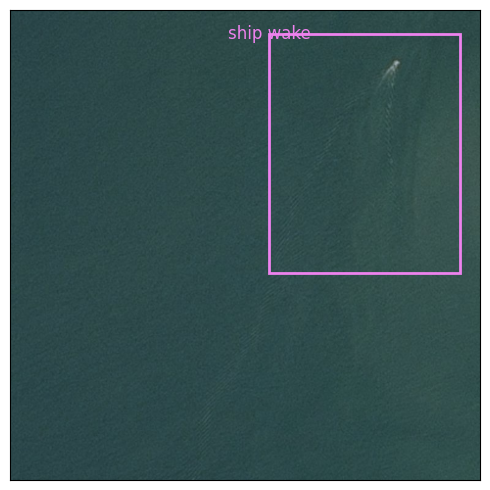

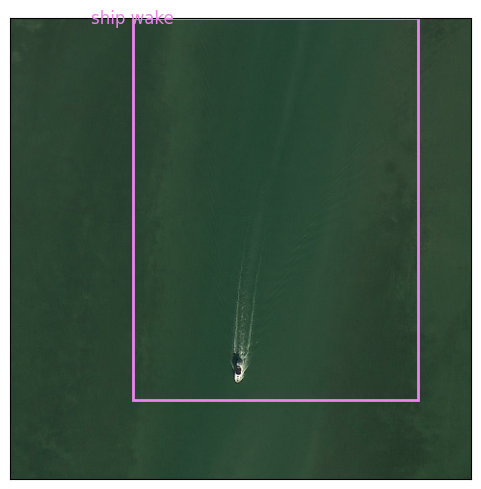

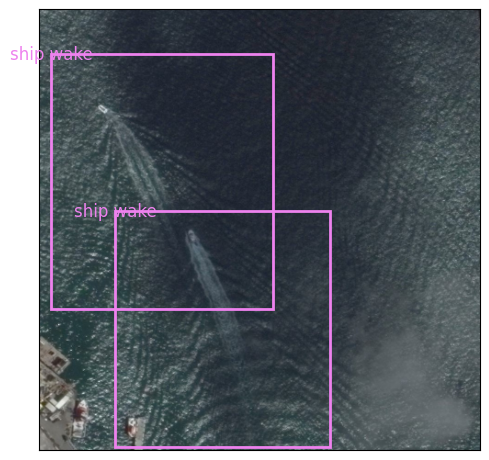

In [9]:
model_config = {
    "num_classes": 2,
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["map"]
}
model = FasterRCNN(model_config)
model.prepare()

model_path = "/home/dragik/data/FAIR_EO/experiments/SWIM_ship/checkpoint.pth.tar"
labels = ["no-data", "ship wake"]
transform = Resize()
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/SWIM_ship/SWIM_Dataset_1.0.0/JPEGImages/00022.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/SWIM_ship/SWIM_Dataset_1.0.0/JPEGImages/03452.jpg')
fig = model.detect_objects(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/SWIM_ship/SWIM_Dataset_1.0.0/JPEGImages/06052.jpg')
fig = model.detect_objects(image, labels, transform)